In [2]:
#Step1: Load the Dataset
import pandas as pd 
df=pd.read_csv("HR_Employees_Messy_Raw.csv")
print(df.head())
print("shape:",df.shape)
print(df.info())

  EmployeeID   Age  Gender  Department               JobRole Education  \
0   EMP00001  38.0    Male  Operations  Operations Executive   College   
1   EMP00002  35.0    Male  Operations  Operations Executive   College   
2   EMP00003  29.0  Female     Finance            Accountant    Master   
3   EMP00004  34.0  Female       Sales       Sales Executive   College   
4   EMP00005  39.0  Female       Sales         Sales Manager  Bachelor   

    EducationField MaritalStatus     BusinessTravel OverTime  ...  \
0            Other        Single         Non-Travel      Yes  ...   
1          Medical      Divorced  Travel_Frequently      Yes  ...   
2  Human Resources      Divorced      Travel_Rarely      Yes  ...   
3        Marketing      Divorced         Non-Travel      Yes  ...   
4    Life Sciences        Single  Travel_Frequently       No  ...   

  YearsSinceLastPromotion MonthlyIncome  HourlyRate  JobSatisfaction  \
0                       0       ₹10,400          79              1.0

In [3]:
#Step2: Check the Missing Values
print("Missing values:")
print(df.isnull().sum())

#Check Total Missing Values
print("\nTotal Misiing Values:")
print(df.isnull().sum())

#Check duplicate Records
print("\nDuplicate records:")
print(df.duplicated().sum())

Missing values:
EmployeeID                    0
Age                          20
Gender                        0
Department                   20
JobRole                       0
Education                     0
EducationField               18
MaritalStatus                 0
BusinessTravel                0
OverTime                      0
HireDate                      0
TerminationDate            1216
YearsAtCompany                0
YearsInCurrentRole            0
YearsSinceLastPromotion       0
MonthlyIncome                18
HourlyRate                    0
JobSatisfaction              18
EnvironmentSatisfaction       0
WorkLifeBalance              19
PerformanceRating             0
TrainingTimesLastYear         0
DistanceFromHome              0
Attrition                     0
dtype: int64

Total Misiing Values:
EmployeeID                    0
Age                          20
Gender                        0
Department                   20
JobRole                       0
Education           

In [5]:
#step3: Remove Duplicate Records
df=df.drop_duplicates()
print("Duplicates removed successfully!")
print("New Dataset shape:",df.shape)

Duplicates removed successfully!
New Dataset shape: (1500, 24)


In [6]:

# Step4: Handle Missing Values

# Convert MonthlyIncome into numeric format
df['MonthlyIncome'] = pd.to_numeric(df['MonthlyIncome'].astype(str).str.replace(r'[₹,]', '', regex=True),errors='coerce')

# Fill missing numerical values
df['Age'] = df['Age'].fillna(df['Age'].median())

df['MonthlyIncome'] = df['MonthlyIncome'].fillna(df['MonthlyIncome'].median())

df['JobSatisfaction'] = df['JobSatisfaction'].fillna(df['JobSatisfaction'].median())

df['WorkLifeBalance'] = df['WorkLifeBalance'].fillna(df['WorkLifeBalance'].median())

# Fill missing categorical values
df['Department'] = df['Department'].fillna(df['Department'].mode()[0])

df['EducationField'] = df['EducationField'].fillna(df['EducationField'].mode()[0])

print("Missing values handled successfully!")


Missing values handled successfully!


In [7]:
#Step5: Verify Missing Values
print("Missing Values after cleaning:")
print(df.isnull().sum())
print("Total Missing Values:",df.isnull().sum().sum())

Missing Values after cleaning:
EmployeeID                    0
Age                           0
Gender                        0
Department                    0
JobRole                       0
Education                     0
EducationField                0
MaritalStatus                 0
BusinessTravel                0
OverTime                      0
HireDate                      0
TerminationDate            1191
YearsAtCompany                0
YearsInCurrentRole            0
YearsSinceLastPromotion       0
MonthlyIncome                 0
HourlyRate                    0
JobSatisfaction               0
EnvironmentSatisfaction       0
WorkLifeBalance               0
PerformanceRating             0
TrainingTimesLastYear         0
DistanceFromHome              0
Attrition                     0
dtype: int64
Total Missing Values: 1191


In [7]:
#Step6: Convert Date Columns
df['Hiredate']=pd.to_datetime(df['HireDate'],errors='coerce')
df['TerminationDate']=pd.to_datetime(df['TerminationDate'],errors='coerce')
print("Date columns converted successfully!")
print(df[['Hiredate','TerminationDate']].head())

Date columns converted successfully!
    Hiredate TerminationDate
0 2023-01-07             NaT
1 2024-01-10             NaT
2 2018-09-15             NaT
3 2025-06-10             NaT
4 2025-01-27             NaT


In [8]:
#Step7: Employee Attrition Analysis
# Total Employees
print("Total Employees:",len(df))

#Attrition Count
print("\nAttrition Count:")
print(df['Attrition'].value_counts())

#Department-wise Attrition 
print("\nDepartment-wise Attrition:")
print(pd.crosstab(df['Department'],df['Attrition']))

Total Employees: 1500

Attrition Count:
Attrition
No     1138
Yes     293
NO       38
no       15
yes      10
YES       6
Name: count, dtype: int64

Department-wise Attrition:
Attrition               NO   No  YES  Yes  no  yes
Department                                        
FINANCE                  0    7    0    1   0    0
Finance                  6  184    3   46   3    1
HUMAN RESOURCES          0    5    0    0   0    0
Human Resources         11  185    1   64   5    3
IT                       7  178    0   50   3    2
OPERATIONS               0    6    0    1   0    0
Operations               4  186    0   43   2    1
RESEARCH & DEVELOPMENT   0    9    0    1   0    0
Research & Development   5  164    0   40   2    3
SALES                    0    8    0    2   0    0
Sales                    4  185    2   43   0    0
finance                  0    3    0    0   0    0
human resources          0    5    0    0   0    0
it                       0    1    0    1   0    0
operatio

In [9]:
#Step8: Calculate Attrition Rate
total_employees=len(df)
employees_left=(df['Attrition']=='yes').sum()
attrition_rate=(employees_left/total_employees)*100
print("Total Employees:",total_employees)
print("Employees Left:",employees_left)
print("Attrition Rate:",round(attrition_rate,2),"%")

Total Employees: 1500
Employees Left: 10
Attrition Rate: 0.67 %


In [24]:
# Step 9: Clean Attrition and Department

# Standardize Attrition values
df['Attrition'] = df['Attrition'].astype(str).str.strip().str.lower()

# Standardize Department names
df['Department'] = df['Department'].astype(str).str.strip().str.upper()

# Check cleaned values
print("Attrition Values:")
print(df['Attrition'].value_counts())

print("\nDepartment Values:")
print(df['Department'].value_counts())

# Department-wise Attrition
print("\nDepartment-wise Attrition:")
print(pd.crosstab(df['Department'], df['Attrition']))

Attrition Values:
Attrition
no     1191
yes     309
Name: count, dtype: int64

Department Values:
Department
HUMAN RESOURCES           279
FINANCE                   254
OPERATIONS                249
SALES                     247
IT                        242
RESEARCH & DEVELOPMENT    229
Name: count, dtype: int64

Department-wise Attrition:
Attrition                no  yes
Department                      
FINANCE                 203   51
HUMAN RESOURCES         211   68
IT                      189   53
OPERATIONS              203   46
RESEARCH & DEVELOPMENT  185   44
SALES                   200   47


In [25]:

# Step 10: Calculate Correct Attrition Rate

total_employees = len(df)

employees_left = (df['Attrition'] == 'yes').sum()

attrition_rate = (employees_left / total_employees) * 100

print("Total Employees:", total_employees)
print("Employees Left:", employees_left)
print("Employees Stayed:", total_employees - employees_left)
print("Attrition Rate:", round(attrition_rate, 2), "%")


Total Employees: 1500
Employees Left: 309
Employees Stayed: 1191
Attrition Rate: 20.6 %


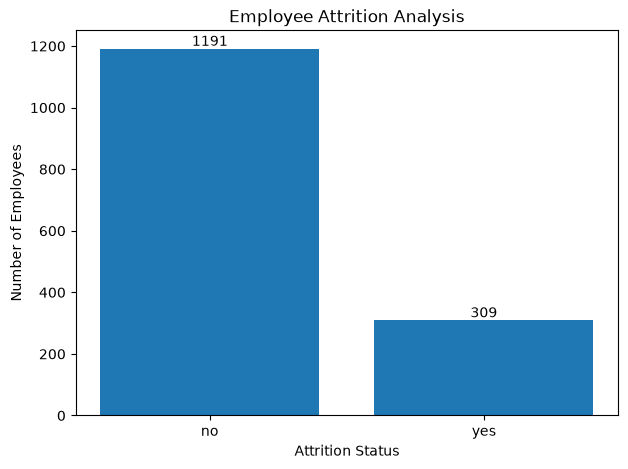

In [26]:
#Step 11: Create Attrition Visualization
import matplotlib.pyplot as plt

# Attrition count
attrition_counts = df['Attrition'].value_counts()

# Create bar chart
plt.figure(figsize=(7, 5))

plt.bar(
    attrition_counts.index,
    attrition_counts.values
)

plt.title('Employee Attrition Analysis')
plt.xlabel('Attrition Status')
plt.ylabel('Number of Employees')

# Display values
for i, value in enumerate(attrition_counts.values):
    plt.text(i, value + 10, str(value), ha='center')

plt.show()


In [28]:

# Step 12: Department-wise Attrition Rate

department_analysis = df.groupby('Department').agg(
    Total_Employees=('Attrition', 'count'),
    Employees_Left=('Attrition', lambda x: (x == 'yes').sum())
)

department_analysis['Attrition_Rate'] = (
    department_analysis['Employees_Left'] /
    department_analysis['Total_Employees']
) * 100

print(department_analysis.round(2))



                        Total_Employees  Employees_Left  Attrition_Rate
Department                                                             
FINANCE                             254              51           20.08
HUMAN RESOURCES                     279              68           24.37
IT                                  242              53           21.90
OPERATIONS                          249              46           18.47
RESEARCH & DEVELOPMENT              229              44           19.21
SALES                               247              47           19.03


In [29]:

# Step 13: Age-wise Attrition Analysis

# Create age groups
df['Age_Group'] = pd.cut(
    df['Age'],
    bins=[18, 25, 30, 35, 40, 50, 60],
    labels=['18-25', '26-30', '31-35', '36-40', '41-50', '51-60'],
    include_lowest=True
)

# Calculate age-wise attrition
age_attrition = df.groupby('Age_Group', observed=False).agg(
    Total_Employees=('Attrition', 'count'),
    Employees_Left=('Attrition', lambda x: (x == 'yes').sum())
)

age_attrition['Attrition_Rate'] = (
    age_attrition['Employees_Left'] /
    age_attrition['Total_Employees']
) * 100

print("Age-wise Attrition Analysis:")
print(age_attrition.round(2))


Age-wise Attrition Analysis:
           Total_Employees  Employees_Left  Attrition_Rate
Age_Group                                                 
18-25                  188              48           25.53
26-30                  224              41           18.30
31-35                  328              76           23.17
36-40                  385              76           19.74
41-50                  319              60           18.81
51-60                   56               8           14.29


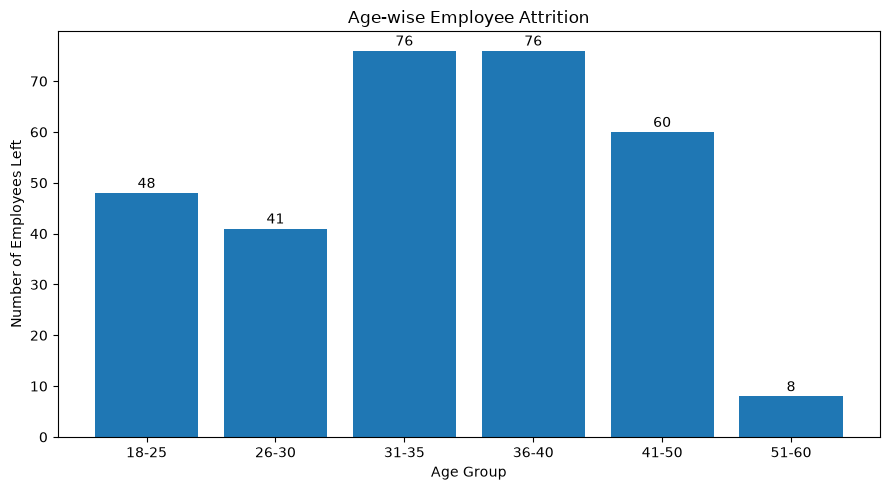

In [30]:


# Step 14: Visualize Age-wise Attrition

plt.figure(figsize=(9, 5))

plt.bar(
    age_attrition.index.astype(str),
    age_attrition['Employees_Left']
)

plt.title('Age-wise Employee Attrition')
plt.xlabel('Age Group')
plt.ylabel('Number of Employees Left')

for i, value in enumerate(age_attrition['Employees_Left']):
    plt.text(i, value + 1, str(value), ha='center')

plt.tight_layout()
plt.show()


In [31]:
# Step 15: Gender-wise Attrition Analysis

# Clean Gender column
df['Gender'] = df['Gender'].astype(str).str.strip().str.title()

# Gender-wise analysis
gender_analysis = df.groupby('Gender').agg(
    Total_Employees=('Attrition', 'count'),
    Employees_Left=('Attrition', lambda x: (x == 'yes').sum())
)

# Calculate attrition rate
gender_analysis['Attrition_Rate'] = (
    gender_analysis['Employees_Left'] /
    gender_analysis['Total_Employees']
) * 100

print("Gender-wise Attrition Analysis:")
print(gender_analysis.round(2))

Gender-wise Attrition Analysis:
        Total_Employees  Employees_Left  Attrition_Rate
Gender                                                 
Female              760             152           20.00
Male                740             157           21.22


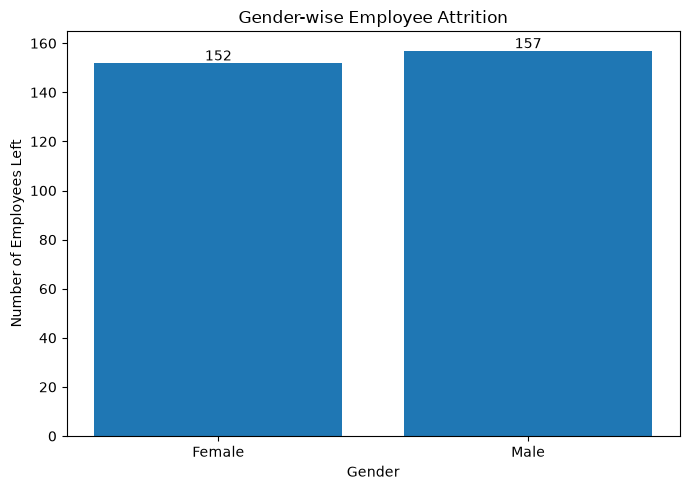

In [32]:

# Step 16: Gender-wise Attrition Visualization

gender_attrition = df.groupby('Gender')['Attrition'].apply(
    lambda x: (x == 'yes').sum()
)

plt.figure(figsize=(7, 5))

plt.bar(
    gender_attrition.index,
    gender_attrition.values
)

plt.title('Gender-wise Employee Attrition')
plt.xlabel('Gender')
plt.ylabel('Number of Employees Left')

for i, value in enumerate(gender_attrition.values):
    plt.text(i, value + 1, str(value), ha='center')

plt.tight_layout()
plt.show()

In [33]:
# Step 17: Salary-wise Attrition Analysis

# Create salary groups
df['Salary_Group'] = pd.cut(
    df['MonthlyIncome'],
    bins=[0, 3000, 5000, 8000, 12000, float('inf')],
    labels=['Low', 'Lower-Middle', 'Middle', 'Upper-Middle', 'High']
)

# Calculate salary-wise attrition
salary_analysis = df.groupby('Salary_Group', observed=False).agg(
    Total_Employees=('Attrition', 'count'),
    Employees_Left=('Attrition', lambda x: (x == 'yes').sum())
)

# Calculate attrition rate
salary_analysis['Attrition_Rate'] = (
    salary_analysis['Employees_Left'] /
    salary_analysis['Total_Employees']
) * 100

print("Salary-wise Attrition Analysis:")
print(salary_analysis.round(2))

Salary-wise Attrition Analysis:
              Total_Employees  Employees_Left  Attrition_Rate
Salary_Group                                                 
Low                        32               9           28.12
Lower-Middle              184              36           19.57
Middle                    669             135           20.18
Upper-Middle              567             117           20.63
High                       48              12           25.00


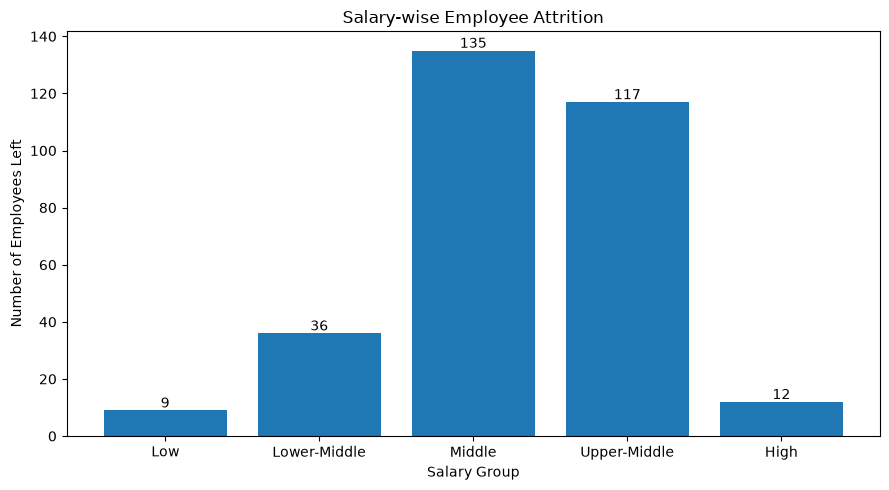

In [34]:
# Step 18: Salary-wise Attrition Visualization

plt.figure(figsize=(9, 5))

plt.bar(
    salary_analysis.index.astype(str),
    salary_analysis['Employees_Left']
)

plt.title('Salary-wise Employee Attrition')
plt.xlabel('Salary Group')
plt.ylabel('Number of Employees Left')

for i, value in enumerate(salary_analysis['Employees_Left']):
    plt.text(i, value + 1, str(value), ha='center')

plt.tight_layout()
plt.show()

In [35]:
# Step 19: Job Role-wise Attrition Analysis

# Clean JobRole column
df['JobRole'] = df['JobRole'].astype(str).str.strip().str.title()

# Calculate job role-wise attrition
jobrole_analysis = df.groupby('JobRole').agg(
    Total_Employees=('Attrition', 'count'),
    Employees_Left=('Attrition', lambda x: (x == 'yes').sum())
)

# Calculate attrition rate
jobrole_analysis['Attrition_Rate'] = (
    jobrole_analysis['Employees_Left'] /
    jobrole_analysis['Total_Employees']
) * 100

print("Job Role-wise Attrition Analysis:")
print(jobrole_analysis.round(2))

Job Role-wise Attrition Analysis:
                       Total_Employees  Employees_Left  Attrition_Rate
JobRole                                                               
Accountant                          84              17           20.24
Data Analyst                        77              15           19.48
Finance Manager                     89              16           17.98
Financial Analyst                   84              20           23.81
Hr Executive                        80              19           23.75
Hr Manager                          88              19           21.59
It Support                          89              19           21.35
Laboratory Technician               78              15           19.23
Operations Executive               106              20           18.87
Operations Manager                  63              17           26.98
Recruiter                           96              25           26.04
Research Director                   78     

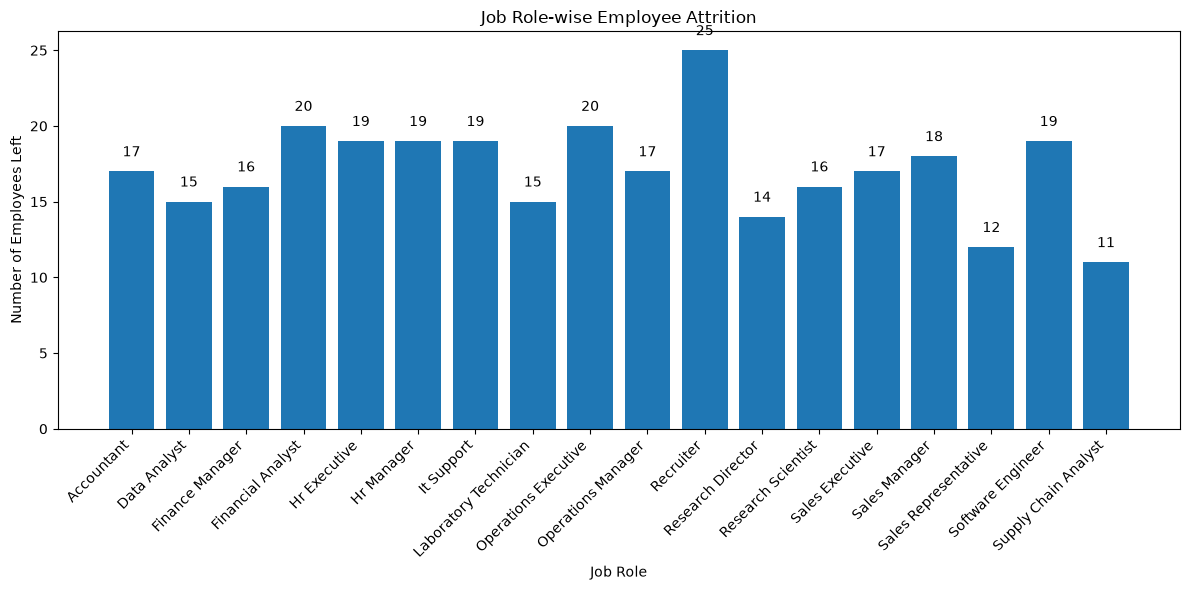

In [36]:
# Step 20: Job Role-wise Attrition Visualization

jobrole_attrition = jobrole_analysis['Employees_Left']

plt.figure(figsize=(12, 6))

plt.bar(
    jobrole_attrition.index,
    jobrole_attrition.values
)

plt.title('Job Role-wise Employee Attrition')
plt.xlabel('Job Role')
plt.ylabel('Number of Employees Left')

plt.xticks(rotation=45, ha='right')

for i, value in enumerate(jobrole_attrition.values):
    plt.text(i, value + 1, str(value), ha='center')

plt.tight_layout()
plt.show()

In [37]:
# Step 21: Education-wise Attrition Analysis

# Clean EducationField column
df['EducationField'] = (
    df['EducationField']
    .astype(str)
    .str.strip()
    .str.title()
)

# Calculate education-wise attrition
education_analysis = df.groupby('EducationField').agg(
    Total_Employees=('Attrition', 'count'),
    Employees_Left=('Attrition', lambda x: (x == 'yes').sum())
)

# Calculate attrition rate
education_analysis['Attrition_Rate'] = (
    education_analysis['Employees_Left'] /
    education_analysis['Total_Employees']
) * 100

print("Education-wise Attrition Analysis:")
print(education_analysis.round(2))

Education-wise Attrition Analysis:
                  Total_Employees  Employees_Left  Attrition_Rate
EducationField                                                   
Human Resources               234              54           23.08
Life Sciences                 258              56           21.71
Marketing                     222              47           21.17
Medical                       226              41           18.14
Other                         295              51           17.29
Technical Degree              265              60           22.64


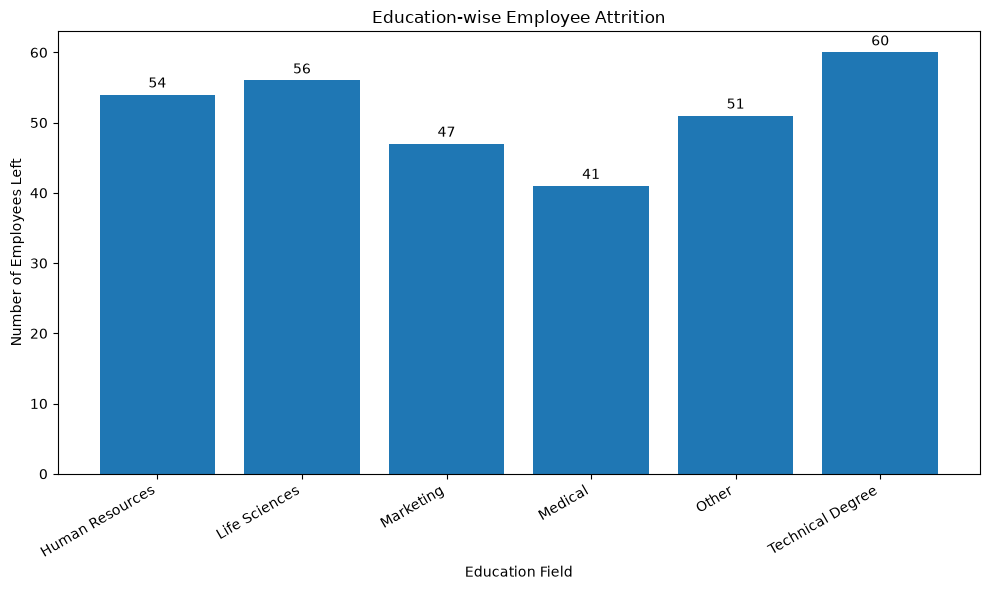

In [38]:
# Step 22: Education-wise Attrition Visualization

plt.figure(figsize=(10, 6))

plt.bar(
    education_analysis.index,
    education_analysis['Employees_Left']
)

plt.title('Education-wise Employee Attrition')
plt.xlabel('Education Field')
plt.ylabel('Number of Employees Left')

plt.xticks(rotation=30, ha='right')

for i, value in enumerate(education_analysis['Employees_Left']):
    plt.text(i, value + 1, str(value), ha='center')

plt.tight_layout()
plt.show()

In [39]:
# Step 23: Experience-wise Attrition Analysis

# Create experience groups
df['Experience_Group'] = pd.cut(
    df['YearsAtCompany'],
    bins=[-1, 1, 3, 5, 10, float('inf')],
    labels=[
        '0-1 Years',
        '2-3 Years',
        '4-5 Years',
        '6-10 Years',
        'Above 10 Years'
    ]
)

# Calculate experience-wise attrition
experience_analysis = df.groupby(
    'Experience_Group',
    observed=False
).agg(
    Total_Employees=('Attrition', 'count'),
    Employees_Left=('Attrition', lambda x: (x == 'yes').sum())
)

# Calculate attrition rate
experience_analysis['Attrition_Rate'] = (
    experience_analysis['Employees_Left'] /
    experience_analysis['Total_Employees']
) * 100

print("Experience-wise Attrition Analysis:")
print(experience_analysis.round(2))

Experience-wise Attrition Analysis:
                  Total_Employees  Employees_Left  Attrition_Rate
Experience_Group                                                 
0-1 Years                     340              95           27.94
2-3 Years                     398              74           18.59
4-5 Years                     379              63           16.62
6-10 Years                    383              77           20.10
Above 10 Years                  0               0             NaN


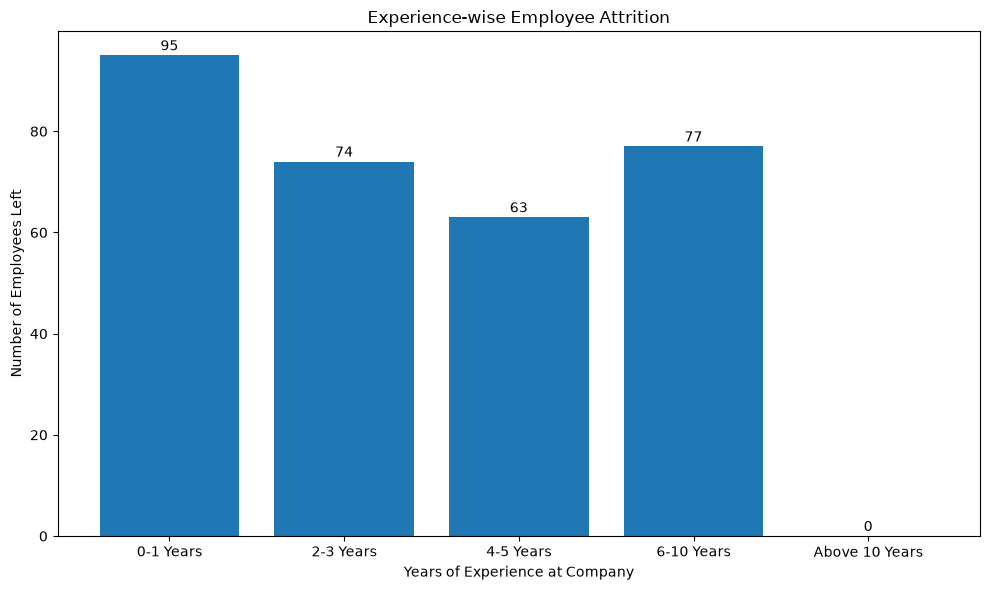

In [40]:
# Step 24: Experience-wise Attrition Visualization

plt.figure(figsize=(10, 6))

plt.bar(
    experience_analysis.index.astype(str),
    experience_analysis['Employees_Left']
)

plt.title('Experience-wise Employee Attrition')
plt.xlabel('Years of Experience at Company')
plt.ylabel('Number of Employees Left')

for i, value in enumerate(experience_analysis['Employees_Left']):
    plt.text(i, value + 1, str(value), ha='center')

plt.tight_layout()
plt.show()

In [41]:
# Step 25: Overtime-wise Attrition Analysis

# Clean OverTime column
df['OverTime'] = (
    df['OverTime']
    .astype(str)
    .str.strip()
    .str.title()
)

# Calculate overtime-wise attrition
overtime_analysis = df.groupby('OverTime').agg(
    Total_Employees=('Attrition', 'count'),
    Employees_Left=('Attrition', lambda x: (x == 'yes').sum())
)

# Calculate attrition rate
overtime_analysis['Attrition_Rate'] = (
    overtime_analysis['Employees_Left'] /
    overtime_analysis['Total_Employees']
) * 100

print("Overtime-wise Attrition Analysis:")
print(overtime_analysis.round(2))

Overtime-wise Attrition Analysis:
          Total_Employees  Employees_Left  Attrition_Rate
OverTime                                                 
No                    765             124           16.21
Yes                   735             185           25.17


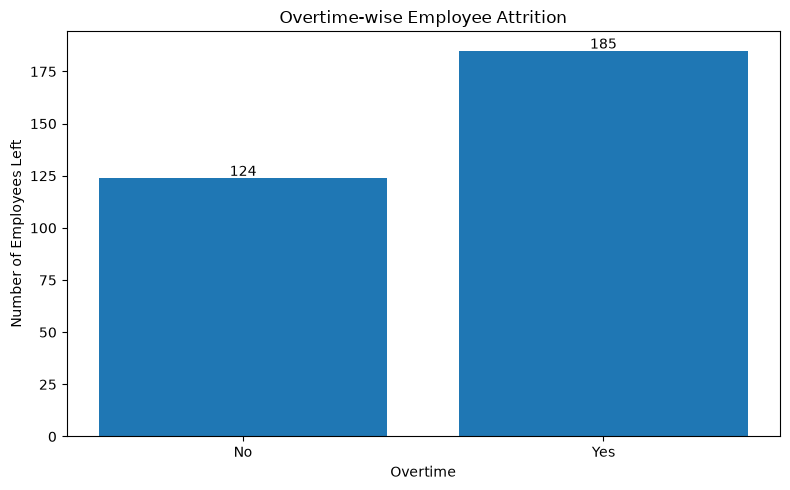

In [42]:
# Step 26: Overtime-wise Attrition Visualization

plt.figure(figsize=(8, 5))

plt.bar(
    overtime_analysis.index,
    overtime_analysis['Employees_Left']
)

plt.title('Overtime-wise Employee Attrition')
plt.xlabel('Overtime')
plt.ylabel('Number of Employees Left')

for i, value in enumerate(overtime_analysis['Employees_Left']):
    plt.text(i, value + 1, str(value), ha='center')

plt.tight_layout()
plt.show()

In [43]:
# Step 27: Job Satisfaction-wise Attrition Analysis

# Create job satisfaction labels
satisfaction_labels = {
    1: 'Low',
    2: 'Medium',
    3: 'High',
    4: 'Very High'
}

df['Satisfaction_Level'] = df['JobSatisfaction'].map(
    satisfaction_labels
)

# Calculate satisfaction-wise attrition
satisfaction_analysis = df.groupby('Satisfaction_Level').agg(
    Total_Employees=('Attrition', 'count'),
    Employees_Left=('Attrition', lambda x: (x == 'yes').sum())
)

# Calculate attrition rate
satisfaction_analysis['Attrition_Rate'] = (
    satisfaction_analysis['Employees_Left'] /
    satisfaction_analysis['Total_Employees']
) * 100

print("Job Satisfaction Analysis:")
print(satisfaction_analysis.round(2))

Job Satisfaction Analysis:
                    Total_Employees  Employees_Left  Attrition_Rate
Satisfaction_Level                                                 
High                            404              84           20.79
Low                             359              62           17.27
Medium                          366              83           22.68
Very High                       371              80           21.56


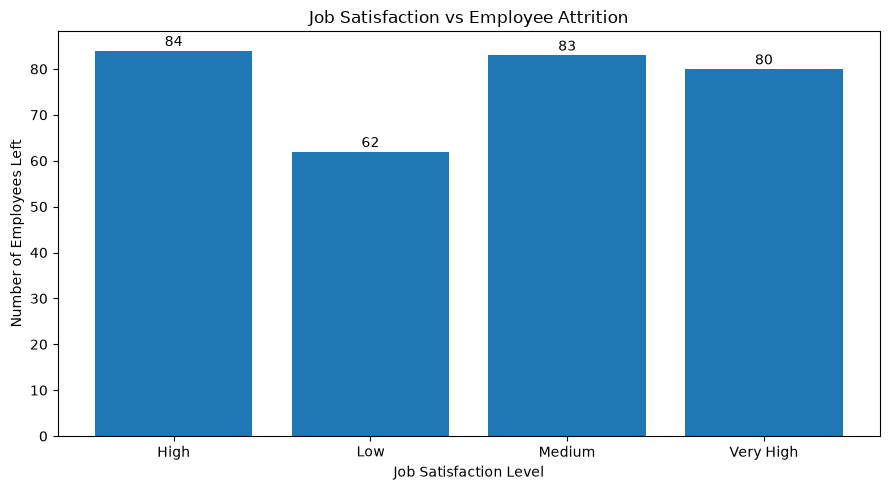

In [44]:
# Step 28: Visualize Job Satisfaction Attrition

plt.figure(figsize=(9, 5))

plt.bar(
    satisfaction_analysis.index,
    satisfaction_analysis['Employees_Left']
)

plt.title('Job Satisfaction vs Employee Attrition')
plt.xlabel('Job Satisfaction Level')
plt.ylabel('Number of Employees Left')

for i, value in enumerate(satisfaction_analysis['Employees_Left']):
    plt.text(i, value + 1, str(value), ha='center')

plt.tight_layout()
plt.show()

In [45]:
# Step 39: Work-Life Balance-wise Attrition Analysis

# Create work-life balance labels
balance_labels = {
    1: 'Bad',
    2: 'Good',
    3: 'Better',
    4: 'Best'
}

df['WorkLifeBalance_Level'] = df['WorkLifeBalance'].map(
    balance_labels
)

# Calculate work-life balance-wise attrition
balance_analysis = df.groupby('WorkLifeBalance_Level').agg(
    Total_Employees=('Attrition', 'count'),
    Employees_Left=('Attrition', lambda x: (x == 'yes').sum())
)

# Calculate attrition rate
balance_analysis['Attrition_Rate'] = (
    balance_analysis['Employees_Left'] /
    balance_analysis['Total_Employees']
) * 100

print("Work-Life Balance Analysis:")
print(balance_analysis.round(2))

Work-Life Balance Analysis:
                       Total_Employees  Employees_Left  Attrition_Rate
WorkLifeBalance_Level                                                 
Bad                                373              85           22.79
Best                               335              70           20.90
Better                             390              79           20.26
Good                               402              75           18.66


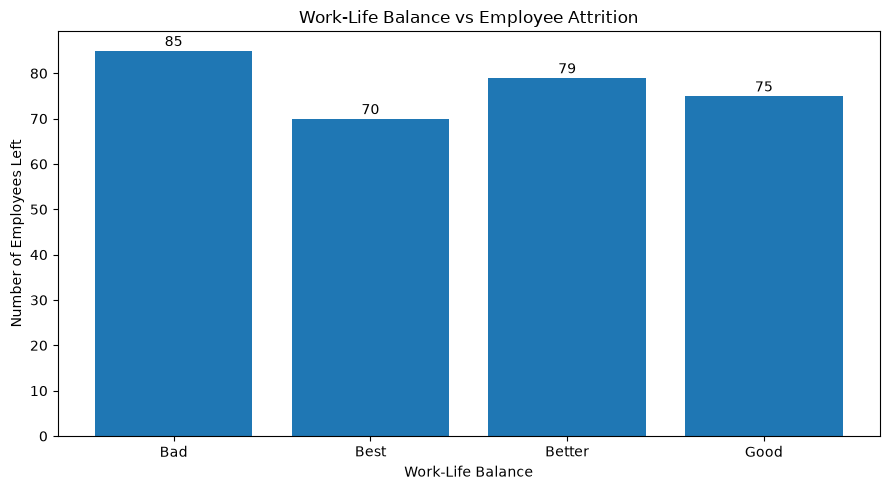

In [46]:
# Step 30: Work-Life Balance Visualization

plt.figure(figsize=(9, 5))

plt.bar(
    balance_analysis.index,
    balance_analysis['Employees_Left']
)

plt.title('Work-Life Balance vs Employee Attrition')
plt.xlabel('Work-Life Balance')
plt.ylabel('Number of Employees Left')

for i, value in enumerate(balance_analysis['Employees_Left']):
    plt.text(i, value + 1, str(value), ha='center')

plt.tight_layout()
plt.show()

Correlation Matrix:
                          Age  YearsAtCompany  YearsInCurrentRole  \
Age                      1.00            0.01               -0.01   
YearsAtCompany           0.01            1.00                0.59   
YearsInCurrentRole      -0.01            0.59                1.00   
YearsSinceLastPromotion  0.01            0.60                0.37   
MonthlyIncome           -0.02            0.01               -0.02   
HourlyRate              -0.02            0.02               -0.00   
JobSatisfaction          0.01           -0.01               -0.04   
EnvironmentSatisfaction  0.02            0.01                0.04   
WorkLifeBalance          0.03           -0.02               -0.05   
PerformanceRating        0.00            0.01               -0.00   
TrainingTimesLastYear    0.02           -0.01                0.01   
DistanceFromHome        -0.01            0.04                0.02   

                         YearsSinceLastPromotion  MonthlyIncome  HourlyRate  \
Age

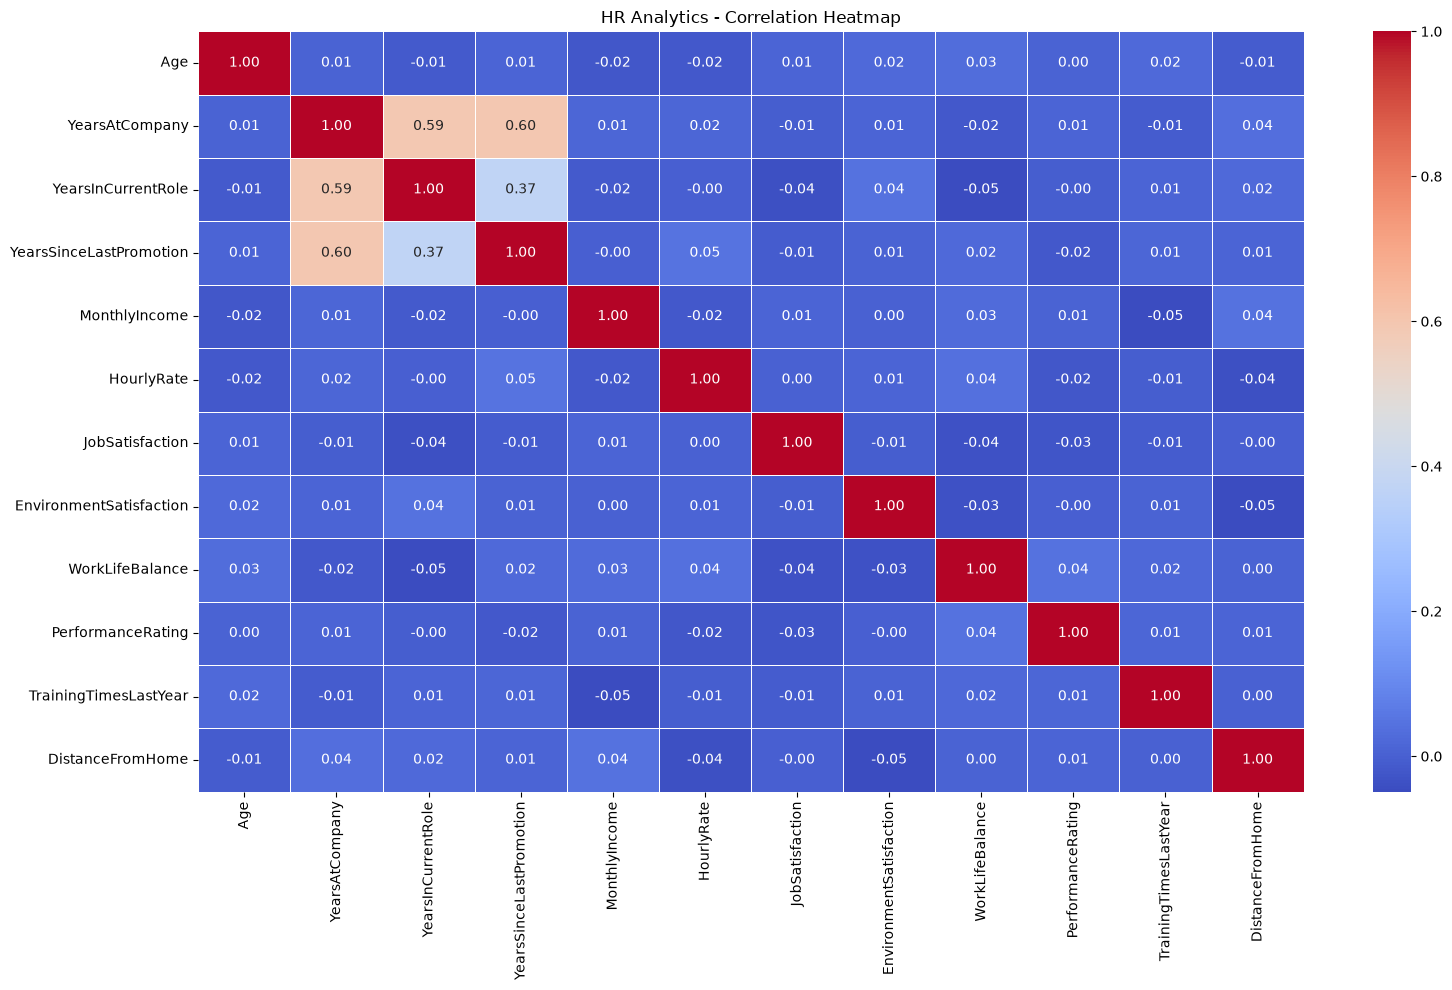

In [47]:
# Step 31: Correlation Analysis

import seaborn as sns
import matplotlib.pyplot as plt

# Select numerical columns
numeric_df = df.select_dtypes(include='number')

# Calculate correlation
correlation = numeric_df.corr()

# Display correlation values
print("Correlation Matrix:")
print(correlation.round(2))

# Create heatmap
plt.figure(figsize=(16, 10))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('HR Analytics - Correlation Heatmap')
plt.tight_layout()
plt.show()

In [48]:
# Step 32: Attrition Correlation

# Convert Attrition into numerical values
df['Attrition_Numeric'] = df['Attrition'].map({
    'no': 0,
    'yes': 1
})

# Calculate correlation with attrition
attrition_corr = df.select_dtypes(
    include='number'
).corr()['Attrition_Numeric'].drop(
    'Attrition_Numeric'
)

# Sort correlation values
attrition_corr = attrition_corr.sort_values()

print("Correlation with Employee Attrition:")
print(attrition_corr.round(3))

Correlation with Employee Attrition:
YearsSinceLastPromotion   -0.069
YearsAtCompany            -0.066
Age                       -0.045
YearsInCurrentRole        -0.041
PerformanceRating         -0.033
EnvironmentSatisfaction   -0.026
HourlyRate                -0.024
WorkLifeBalance           -0.011
MonthlyIncome             -0.005
DistanceFromHome           0.010
TrainingTimesLastYear      0.027
JobSatisfaction            0.030
Name: Attrition_Numeric, dtype: float64


In [49]:
# Step 35: Final HR Analytics EDA Summary

print("=" * 55)
print("       HR ANALYTICS - FINAL EDA SUMMARY")
print("=" * 55)

# 1. Overall Employee Statistics
total_employees = len(df)

employees_left = (df['Attrition'] == 'yes').sum()

employees_stayed = (df['Attrition'] == 'no').sum()

attrition_rate = (employees_left / total_employees) * 100

print("\n1. OVERALL EMPLOYEE STATISTICS")
print("Total Employees:", total_employees)
print("Employees Left:", employees_left)
print("Employees Stayed:", employees_stayed)
print("Attrition Rate:", round(attrition_rate, 2), "%")

# 2. Department Analysis
department_summary = df.groupby('Department').agg(
    Total_Employees=('Attrition', 'count'),
    Employees_Left=('Attrition',
                    lambda x: (x == 'yes').sum())
)

department_summary['Attrition_Rate'] = (
    department_summary['Employees_Left'] /
    department_summary['Total_Employees']
) * 100

print("\n2. DEPARTMENT ANALYSIS")
print(department_summary.round(2))

# 3. Age Analysis
print("\n3. AGE ANALYSIS")
print("Average Employee Age:", round(df['Age'].mean(), 2))

# 4. Salary Analysis
print("\n4. SALARY ANALYSIS")
print("Average Monthly Income:",
      round(df['MonthlyIncome'].mean(), 2))

# 5. Gender Analysis
print("\n5. GENDER ANALYSIS")
print(pd.crosstab(df['Gender'], df['Attrition']))

# 6. Overtime Analysis
print("\n6. OVERTIME ANALYSIS")
print(pd.crosstab(df['OverTime'], df['Attrition']))

print("\n" + "=" * 55)
print("          EDA ANALYSIS COMPLETED")
print("=" * 55)

       HR ANALYTICS - FINAL EDA SUMMARY

1. OVERALL EMPLOYEE STATISTICS
Total Employees: 1500
Employees Left: 309
Employees Stayed: 1191
Attrition Rate: 20.6 %

2. DEPARTMENT ANALYSIS
                        Total_Employees  Employees_Left  Attrition_Rate
Department                                                             
FINANCE                             254              51           20.08
HUMAN RESOURCES                     279              68           24.37
IT                                  242              53           21.90
OPERATIONS                          249              46           18.47
RESEARCH & DEVELOPMENT              229              44           19.21
SALES                               247              47           19.03

3. AGE ANALYSIS
Average Employee Age: 35.33

4. SALARY ANALYSIS
Average Monthly Income: 7544.18

5. GENDER ANALYSIS
Attrition   no  yes
Gender             
Female     608  152
Male       583  157

6. OVERTIME ANALYSIS
Attrition   no  yes
O

In [50]:
# Step 34: Key Business Insights

print("KEY HR BUSINESS INSIGHTS")
print("-" * 40)

# Highest attrition department
highest_department = department_summary[
    'Attrition_Rate'
].idxmax()

print("1. Highest Attrition Department:",
      highest_department)

# Average employee age
print("2. Average Employee Age:",
      round(df['Age'].mean(), 2))

# Average monthly income
print("3. Average Monthly Income:",
      round(df['MonthlyIncome'].mean(), 2))

# Overtime attrition rate
overtime_rate = df.groupby('OverTime')['Attrition'].apply(
    lambda x: (x == 'yes').mean() * 100
)

print("\n4. Overtime-wise Attrition Rate:")
print(overtime_rate.round(2))

# Overall attrition
print("\n5. Overall Attrition Rate:",
      round(attrition_rate, 2), "%")

KEY HR BUSINESS INSIGHTS
----------------------------------------
1. Highest Attrition Department: HUMAN RESOURCES
2. Average Employee Age: 35.33
3. Average Monthly Income: 7544.18

4. Overtime-wise Attrition Rate:
OverTime
No     16.21
Yes    25.17
Name: Attrition, dtype: float64

5. Overall Attrition Rate: 20.6 %


In [51]:
# Step 35: Export Cleaned HR Dataset

# Export dataset to CSV
df.to_csv('HR_Analytics_Cleaned.csv', index=False)

print("Dataset exported successfully!")

print("File Name: HR_Analytics_Cleaned.csv")

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Dataset exported successfully!
File Name: HR_Analytics_Cleaned.csv
Total Rows: 1500
Total Columns: 31


In [52]:
# Step 36: Verify Exported Dataset

import os
import pandas as pd

file_path = 'HR_Analytics_Cleaned.csv'

if os.path.exists(file_path):

    check_df = pd.read_csv(file_path)

    print("File Exists: Yes")
    print("Rows:", check_df.shape[0])
    print("Columns:", check_df.shape[1])

    print("\nFirst 5 Records:")
    print(check_df.head())

else:
    print("File not found!")

File Exists: Yes
Rows: 1500
Columns: 31

First 5 Records:
  EmployeeID   Age  Gender  Department               JobRole Education  \
0   EMP00001  38.0    Male  OPERATIONS  Operations Executive   College   
1   EMP00002  35.0    Male  OPERATIONS  Operations Executive   College   
2   EMP00003  29.0  Female     FINANCE            Accountant    Master   
3   EMP00004  34.0  Female       SALES       Sales Executive   College   
4   EMP00005  39.0  Female       SALES         Sales Manager  Bachelor   

    EducationField MaritalStatus     BusinessTravel OverTime  ...  \
0            Other        Single         Non-Travel      Yes  ...   
1          Medical      Divorced  Travel_Frequently      Yes  ...   
2  Human Resources      Divorced      Travel_Rarely      Yes  ...   
3        Marketing      Divorced         Non-Travel      Yes  ...   
4    Life Sciences        Single  Travel_Frequently       No  ...   

  TrainingTimesLastYear DistanceFromHome  Attrition    Hiredate  Age_Group  \
0   

In [53]:
# Step 37: Final Data Quality Check

print("Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nDataset Information:")
print(df.info())

Missing Values:
1211

Duplicate Rows:
0

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   EmployeeID               1500 non-null   str           
 1   Age                      1500 non-null   float64       
 2   Gender                   1500 non-null   str           
 3   Department               1500 non-null   str           
 4   JobRole                  1500 non-null   str           
 5   Education                1500 non-null   str           
 6   EducationField           1500 non-null   str           
 7   MaritalStatus            1500 non-null   str           
 8   BusinessTravel           1500 non-null   str           
 9   OverTime                 1500 non-null   str           
 10  HireDate                 1500 non-null   str           
 11  TerminationDate          309 non-null    dat